In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

df = pd.read_csv("../Dataset/dataset_musique_region_transforme.csv")
df.shape()
df.head()

,variete_francaise,pop_rock,rap_hip_hop,classique,jazz,dance,electronique,metal,rnb,soul,reggae,musiques_du_monde,autres_genres,region,region_group,total_genres
0,1,0,0,0,1,0,0,0,0,1,0,0,0,Occitanie,SUD,3
1,0,1,0,0,1,0,0,0,0,0,0,1,0,Pays de la Loire,CENTRE,3
2,1,1,1,0,0,0,0,0,1,0,0,0,0,Hauts-de-France,NORD-OUEST,4
3,1,0,0,1,0,0,0,0,0,0,0,0,0,Provence-Alpes-Côte d'Azur,SUD,2
4,1,0,0,0,1,0,0,0,0,0,0,1,0,Auvergne-Rhône-Alpes,Auvergne-Rhône-Alpes,3


## Variables cible (Y) et variables explicatives (X)

In [12]:
# préférences musicales
X = df.drop(columns=["region", "region_group", "total_genres"])

# régions cibles
Y = df["region_group"]

## Train step

#### Séparer les données 80/20

In [15]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

print("Train :", X_train.shape)
print("Test :", X_test.shape)

Train : (1588, 13)
Test : (398, 13)


### Entrainer le modèle sur le train

In [16]:
# Création du modèle
# modèle de classification car on détermine une classe, ici une région transformée
modele = LogisticRegression(max_iter=1000)

# Entraînement du modèle
modele.fit(X_train, Y_train)

LogisticRegression(max_iter=1000)

### Prédit la région transformée des 398 personnes du test

In [18]:
Y_pred = modele.predict(X_test)

print(Y_pred[:20])

['NORD-OUEST' 'NORD-OUEST' 'NORD-OUEST' 'NORD-OUEST' 'Île-de-France'
 'NORD-OUEST' 'Île-de-France' 'Île-de-France' 'NORD-OUEST' 'CENTRE'
 'Île-de-France' 'Île-de-France' 'NORD-OUEST' 'NORD-OUEST' 'Île-de-France'
 'NORD-OUEST' 'Île-de-France' 'NORD-OUEST' 'Île-de-France'
 'Auvergne-Rhône-Alpes']


Les zones NORD-OUEST et Ile de France dominent sur ces premières prédictions

## Test step

### Précision (Accuracy) du modèle et F1-Score

In [24]:
print("Accuracy :", accuracy_score(Y_test, Y_pred))
print("Accuracy de référence :", Y_test.value_counts(normalize=True).max())
print("F1-score :", f1_score(Y_test, Y_pred, average="macro"))

Accuracy : 0.22110552763819097
Accuracy de référence : 0.20351758793969849
F1-score : 0.13744349580035348


On remarque quand même une légère amélioration entre l'accuracy et l'accuracy de référence : le modèle améliore la précision.
Néanmoins, l'accuracy reste relativement faible (1,76 point de mieux que la baseline).
Le F1-score vient confirmer que le modèle reconnaît globalement mal les différentes régions/zones
Plusieurs choses peuvent venir expliquer ces résultats : 
- Le modèle utilise un trop petit dataset ce qui ne lui permet pas d'être précis et de faire des bonnes prédictions
- Les goûts musicaux sont trop "homogène" pour chaque région (par exemple le rap et la pop sont écoutés partout en france et le modèle a du mal distinguer les régions)
- Il n'y a pas de coefficient pour les goûts musicaux, les variables sont binaires
- La regression logistique peut etre inadaptée



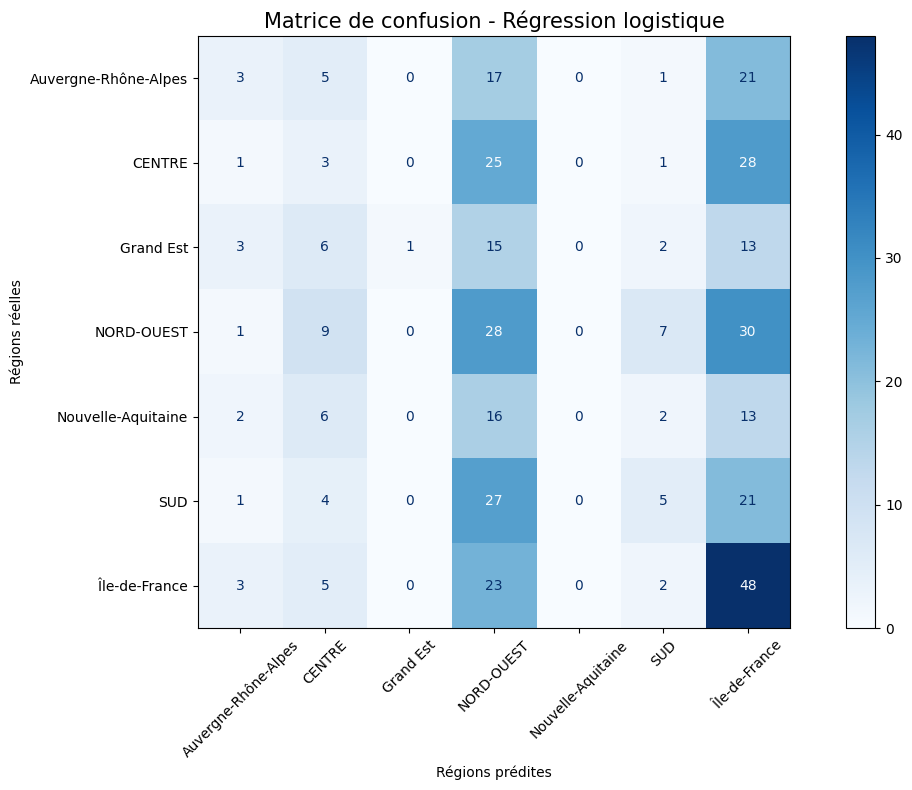

In [26]:
fig, ax = plt.subplots(figsize=(12, 8))

ConfusionMatrixDisplay.from_predictions(
    Y_test,
    Y_pred,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Matrice de confusion - Régression logistique", fontsize=15)
ax.set_xlabel("Régions prédites")
ax.set_ylabel("Régions réelles")

plt.tight_layout()
plt.show()

Accuracy de référence : 0.20351758793969849
